# Imports

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

from torchvision import transforms
from PIL import Image

from tqdm import tqdm

from torcheval.metrics import WordErrorRate
from torchmetrics.text import CharErrorRate

# Functions & Utils

In [ ]:
def find_unused_characters(image_folder, all_chars):
    used_chars = set()

    for filename in os.listdir(image_folder):
        name_part = filename.split('_')[1].split('.')[0]
        
        for char in name_part:
            used_chars.add(char)

    unused_chars = all_chars - used_chars
    
    return unused_chars

all_chars = set('آابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی')

unused_characters = find_unused_characters('./dataset/test/', all_chars)

print("Unused characters in the dataset: ", unused_characters)


Unused characters in the dataset:  {'پ', 'ژ', 'ظ', 'ع', 'ث', 'ط'}


In [3]:
# Parameters
device = 'cuda' if torch.cuda.is_available() else 'cpu'

persian_alphabet = ' آابتجچحخدذرزسشصضغفقکگلمنوهی'

num_classes = len(persian_alphabet)  # Number of characters + 1 for the CTC blank label

target_length = 20

width = 128
height = 32

batch_size_train = 8
batch_size_valid = 217
batch_size_test = 217

seed = 1

use_comet = False

In [5]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [6]:
def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

In [ ]:
class CTCLabelConverter(object):

    def __init__(self, character):
        dict_character = list(character)

        self.dict = {}
        for i, char in enumerate(dict_character):
            self.dict[char] = i + 1

        self.character = ['[CTCblank]'] + dict_character

    def encode(self, text, batch_max_length=target_length):
        length = [len(s) for s in text]

        batch_text = torch.LongTensor(len(text), batch_max_length).fill_(0)
        for i, t in enumerate(text):
            text = list(t)
            text = [self.dict[char] for char in text]
            batch_text[i][:len(text)] = torch.LongTensor(text)
        return (batch_text.to(device), torch.IntTensor(length).to(device))

    def decode(self, text_index, length):
        texts = []
        for index, l in enumerate(length):
            t = text_index[index, :]

            char_list = []
            for i in range(l):
                if t[i] != 0 and (not (i > 0 and t[i - 1] == t[i])):
                    char_list.append(self.character[t[i]])
            text = ''.join(char_list)

            texts.append(text)
        return texts

# Dataset

In [ ]:
class PersianOCRDataset(Dataset):
    def __init__(self, image_folder, converter, transform=None):
        self.image_folder = image_folder
        self.transform = transform
        self.image_files = [f for f in os.listdir(image_folder) if f.endswith('.png')]
        self.converter = converter

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.image_folder, img_name)
        
        image = Image.open(img_path).convert('L')
        
        if self.transform:
            image = self.transform(image)
        
        label = img_name.split('_')[1].replace('.png', '')
        
        label_idx = self.converter.encode([label])
        return image, label_idx[0]

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.Resize((height, width)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Resize((height, width)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [10]:
converter = CTCLabelConverter(persian_alphabet)

train_set = PersianOCRDataset('./dataset/train/', converter, transform=train_transform)
valid_set = PersianOCRDataset('./dataset/valid/', converter, transform=test_transform)
test_set = PersianOCRDataset('./dataset/test/', converter, transform=test_transform)

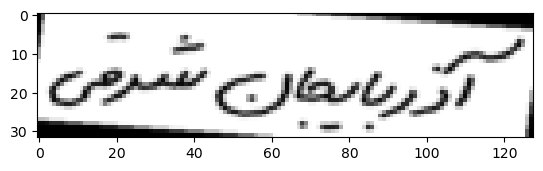

In [11]:
plt.imshow(np.array(train_set[0][0]).squeeze(), cmap='gray')

In [12]:
train_set[0][1]

tensor([[ 2, 11, 12,  4,  3, 28,  6,  3, 25,  1, 15, 12, 20, 28,  0,  0,  0,  0,
          0,  0]], device='cuda:0')

# Model

In [13]:
def activation_layer(activation = "relu", alpha = 0.1, inplace = True):
    if activation == "relu":
        return nn.ReLU(inplace=inplace)
    
    elif activation == "leaky_relu":
        return nn.LeakyReLU(negative_slope=alpha, inplace=inplace)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding):
        super(ConvBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding)
        self.bn = nn.BatchNorm2d(out_channels)
        
    def forward(self, x):
        return self.bn(self.conv(x))


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, skip_conv=True, stride=1, dropout=0.2, activation="relu"):
        super(ResidualBlock, self).__init__()
        self.convb1 = ConvBlock(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.act1 = activation_layer(activation)

        self.convb2 = ConvBlock(out_channels, out_channels, kernel_size=3, stride=1, padding=1)

        self.dropout = nn.Dropout(p=dropout)
        
        self.shortcut = None
        if skip_conv:
            if stride != 1 or in_channels != out_channels:
                self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride)

        self.act2 = activation_layer(activation)
        
    def forward(self, x):
        skip = x
        
        out = self.act1(self.convb1(x))
        out = self.convb2(out)

        if self.shortcut is not None:
            out += self.shortcut(skip)

        out = self.act2(out)
        out = self.dropout(out)
        
        return out

In [42]:
class Network(nn.Module):
    def __init__(self, num_chars: int, activation = "relu", dropout = 0.5):
        super(Network, self).__init__()

        self.rb1 = ResidualBlock(1, 16, skip_conv = True, stride=1, activation=activation, dropout=dropout)
        self.rb2 = ResidualBlock(16, 16, skip_conv = True, stride=2, activation=activation, dropout=dropout)
        self.rb3 = ResidualBlock(16, 32, skip_conv = False, stride=1, activation=activation, dropout=dropout)

        self.rb4 = ResidualBlock(32, 32, skip_conv = True, stride=2, activation=activation, dropout=dropout)
        self.rb5 = ResidualBlock(32, 64, skip_conv = False, stride=1, activation=activation, dropout=dropout)

        self.lstm = nn.LSTM(64, 128, bidirectional=True, num_layers=2, batch_first=True)
        self.lstm_dropout = nn.Dropout(p=dropout)

        self.output = nn.Linear(256, num_chars + 1)

    def forward(self, images):

        x = self.rb1(images)
        x = self.rb2(x)
        x = self.rb3(x)
        x = self.rb4(x)
        x = self.rb5(x)

        x = x.reshape(x.size(0), -1, x.size(1))

        x, _ = self.lstm(x)
        x = self.lstm_dropout(x)

        x = self.output(x)
        x = F.log_softmax(x, 2)
        return x

In [14]:
def collate_fn(batch):
    images, labels = zip(*batch)
    
    images = torch.stack(images, 0)
    
    max_len = max([len(label) for label in labels])
    
    padded_labels = []
    for label in labels:
        padding = torch.zeros(max_len - len(label), dtype=torch.long)
        padded_label = torch.cat([label, padding], dim=0)
        padded_labels.append(padded_label)
    
    padded_labels = torch.stack(padded_labels, 0)
    
    return images, padded_labels


In [ ]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, converter, epoch=None):
    model.train()
    loss_train = AverageMeter()
    cer_train = CharErrorRate().to(device)
    wer_train = WordErrorRate().to(device)
    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.squeeze().to(device)
            

            input_lengths = torch.full(size=(inputs.size(0),), fill_value=32, dtype=torch.long)
            target_lengths = torch.tensor([len(t[t != 0]) for t in targets], dtype=torch.long)  # Actual lengths before padding

            outputs = model(inputs)
            outputs1 = outputs.permute(1,0,2)
            loss = loss_fn(outputs1, targets, input_lengths, target_lengths)

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            loss_train.update(loss.item())
            cer_output = converter.decode(outputs.argmax(dim=2), input_lengths)
            cer_targets = converter.decode(targets, target_lengths)
            cer_train.update(cer_output, cer_targets)
            cer_train.compute()
            wer_train.update(cer_output, cer_targets)
            wer_train.compute()
            tepoch.set_postfix(loss=loss_train.avg, cer=cer_train.compute().item(), wer=wer_train.compute().item())
    return model, loss_train.avg, cer_train.compute().item(), wer_train.compute().item()

In [ ]:
def validation(model, test_loader, loss_fn, converter):
    model.eval()
    with torch.no_grad():
        loss_valid = AverageMeter()
        cer_valid = CharErrorRate().to(device)
        wer_valid = WordErrorRate().to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.squeeze().to(device)

            input_lengths = torch.full(size=(inputs.size(0),), fill_value=32, dtype=torch.long)
            target_lengths = torch.tensor([len(t[t != 0]) for t in targets], dtype=torch.long)  # Actual lengths before padding

            outputs = model(inputs)
            outputs1 = outputs.permute(1,0,2)
            loss = loss_fn(outputs1, targets, input_lengths, target_lengths)
      
            loss_valid.update(loss.item())
            cer_output = converter.decode(outputs.argmax(dim=2), input_lengths)
            cer_targets = converter.decode(targets, target_lengths)
            cer_valid.update(cer_output, cer_targets)
            cer_valid.compute()
            wer_valid.update(cer_output, cer_targets)
            wer_valid.compute()
    return loss_valid.avg, cer_valid.compute().item(), wer_valid.compute().item()

In [20]:
set_seed(seed)

train_loader = DataLoader(train_set, batch_size=batch_size_train, shuffle=True)#,collate_fn=collate_fn)
valid_loader = DataLoader(valid_set, batch_size=batch_size_valid, shuffle=True)#,collate_fn=collate_fn)
test_loader = DataLoader(test_set, batch_size=batch_size_test, shuffle=True)

# Training

### Initial Loss

In [ ]:
set_seed(seed)

model = Network(num_classes, activation='relu', dropout=0.5).to(device)
loss_fn = nn.CTCLoss(blank=0, zero_infinity=True)

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
input_lengths = torch.full(size=(inputs.size(0),), fill_value=32, dtype=torch.long)
target_lengths = torch.tensor([len(t[t != 0]) for t in targets], dtype=torch.long)  # Actual lengths before padding
targets = targets.squeeze().to(device)

with torch.no_grad():
  outputs = model(inputs)
  outputs1 = outputs.permute(1,0,2)
  loss = loss_fn(outputs1, targets, input_lengths, target_lengths)

print(loss)

tensor(6.6862, device='cuda:0')


### Best Learning Rate (Adam optimizer)

In [34]:
set_seed(seed)

loss_fn = nn.CTCLoss(blank=0, zero_infinity=True)

num_epochs = 3

for lr in [0.5, 0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model = Network(num_classes, activation='relu', dropout=0.5).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _, _ = train_one_epoch(model, train_loader, loss_fn, optimizer, converter, epoch + 1)
  print()

LR=0.5


  0%|          | 0/97 [00:00<?, ?batch/s]

Epoch 3: 100%|██████████| 97/97 [00:04<00:00, 22.18batch/s, cer=1.25, loss=82.3, wer=1.06]



LR=0.3


Epoch 3: 100%|██████████| 97/97 [00:04<00:00, 22.07batch/s, cer=1.22, loss=64.3, wer=1.06]



LR=0.1


... (3 outputs left out)


LR=0.001


Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 24.81batch/s, cer=0.914, loss=2.81, wer=1]



LR=0.0001


Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 25.84batch/s, cer=1, loss=3.2, wer=1] 

In [35]:
set_seed(seed)

loss_fn = nn.CTCLoss(blank=0, zero_infinity=True)

num_epochs = 3

for lr in [0.0099, 0.01, 0.012, 0.015, 0.02, 0.03]:
  print(f'LR={lr}')

  model = Network(num_classes, activation='relu', dropout=0.5).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _, _ = train_one_epoch(model, train_loader, loss_fn, optimizer, converter, epoch + 1)
  print()

LR=0.0099


  0%|          | 0/97 [00:00<?, ?batch/s]

Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 25.08batch/s, cer=0.795, loss=2.67, wer=1.01] 



LR=0.01


Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 26.06batch/s, cer=0.798, loss=2.73, wer=1.02]



LR=0.012


... (3 outputs left out)


LR=0.02


Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 25.17batch/s, cer=0.855, loss=2.93, wer=1.01]



LR=0.03


Epoch 3: 100%|██████████| 97/97 [00:03<00:00, 25.04batch/s, cer=0.778, loss=2.6, wer=0.991] 

### Train

In [ ]:
set_seed(seed)

first_lr = 0.01
lr = first_lr

model = Network(num_classes, activation='relu', dropout=0.5).to(device)
loss_fn = nn.CTCLoss(blank=0, zero_infinity=True)  # CTC blank label corresponds to the index 0
optimizer = optim.Adam(model.parameters(), lr=lr)#, weight_decay=1e-1)

In [47]:
#used after 80th epoch
set_seed(seed)

lr = 0.001
optimizer = optim.Adam(model.parameters(), lr=lr)

In [37]:
loss_train_hist = []
loss_valid_hist = []

cer_train_hist = []
cer_valid_hist = []

best_loss_valid = torch.inf
best_wer_valid = torch.inf
epoch_counter = 0

In [ ]:
set_seed(seed)

num_epochs = 10
model_name = 'OCR (relu 0.5 dropout last)'

for epoch in range(num_epochs):
  model, loss_train, cer_train, wer_train = train_one_epoch(model, train_loader, loss_fn, optimizer, converter, epoch_counter + 1)
  
  loss_valid, cer_valid, wer_valid = validation(model, valid_loader, loss_fn, converter) 
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  cer_train_hist.append(cer_train)
  cer_valid_hist.append(cer_valid)

  print(f'Valid: Loss = {loss_valid:.4}, CER = {cer_valid:.4}, WER = {wer_valid:.4}')
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'{model_name} best loss valid lr={first_lr}.pt')
    best_loss_valid = loss_valid
    print('Model Saved. (loss)')

  if wer_valid < best_wer_valid:
    torch.save(model, f'{model_name} best wer valid lr={first_lr}.pt')
    best_wer_valid = wer_valid
    print('Model Saved. (wer)')    
  print()

  epoch_counter += 1

Epoch 101: 100%|██████████| 97/97 [00:05<00:00, 17.70batch/s, cer=0.0226, loss=0.055, wer=0.0962] 


Valid: Loss = 0.3461, CER = 0.06434, WER = 0.1531
Model Saved. (wer)



Epoch 102: 100%|██████████| 97/97 [00:04<00:00, 22.46batch/s, cer=0.0226, loss=0.053, wer=0.0924] 


Valid: Loss = 0.3641, CER = 0.06553, WER = 0.1701



Epoch 103: 100%|██████████| 97/97 [00:04<00:00, 22.18batch/s, cer=0.0279, loss=0.064, wer=0.1]    


Valid: Loss = 0.3528, CER = 0.05903, WER = 0.1599



... (10 outputs left out)

Epoch 109: 100%|██████████| 97/97 [00:04<00:00, 21.84batch/s, cer=0.0142, loss=0.0342, wer=0.0629] 


Valid: Loss = 0.3613, CER = 0.06434, WER = 0.1565



Epoch 110: 100%|██████████| 97/97 [00:04<00:00, 21.99batch/s, cer=0.0137, loss=0.0313, wer=0.0619]


Valid: Loss = 0.3516, CER = 0.06257, WER = 0.1667



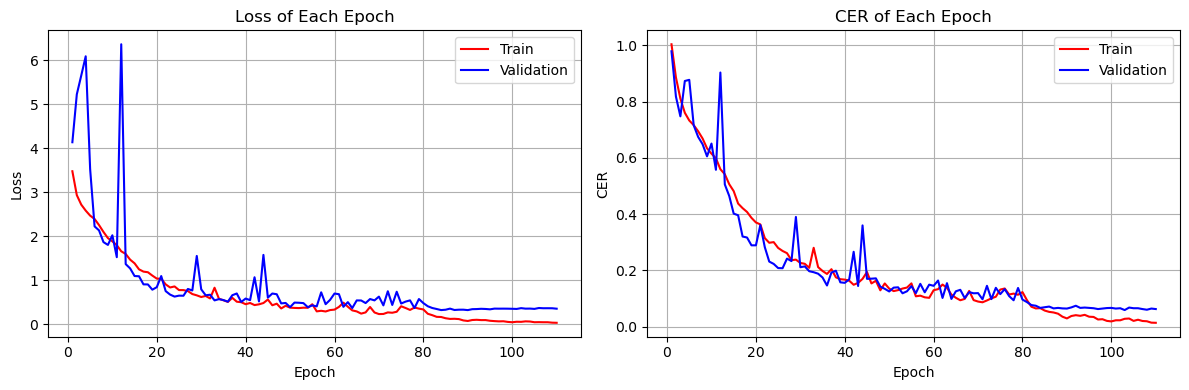

In [ ]:
epochs = list(range(1, epoch_counter + 1))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.lineplot(x=epochs, y=loss_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=loss_valid_hist, label='Validation', color='b')
plt.title('Loss of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs, y=cer_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=cer_valid_hist, label='Validation', color='b')
plt.title('CER of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('CER')
plt.grid(True)

plt.tight_layout()
plt.show()

In [60]:
ocr_data = {
    'loss_train_hist': loss_train_hist,
    'loss_valid_hist': loss_valid_hist,
    'dice_train_hist': cer_train_hist,
    'dice_valid_hist': cer_valid_hist
}

df = pd.DataFrame(ocr_data)

df.to_csv('ocr_data.csv', index=True)
df

,loss_train_hist,loss_valid_hist,dice_train_hist,dice_valid_hist
0,3.473898,4.132363,1.004297,0.979339
1,2.931146,5.220207,0.886281,0.818182
2,2.715283,5.648524,0.811074,0.747934
3,2.579941,6.084432,0.760661,0.873672
4,2.465675,3.522334,0.733223,0.877804
...,...,...,...,...
105,0.045916,0.367166,0.024628,0.065525
106,0.044006,0.361673,0.020165,0.062574
107,0.043835,0.362359,0.019174,0.060213
108,0.034232,0.361324,0.014215,0.064345


# Evaluations

In [ ]:
with torch.no_grad():
    x, y = next(iter(test_loader))
    x = x.to(device)
    y = y.squeeze().to(device)

    input_lengths = torch.full(size=(x.size(0),), fill_value=32, dtype=torch.long)
    target_lengths = torch.tensor([len(t[t != 0]) for t in y], dtype=torch.long)
    outputs = model(x)

    cer_output = converter.decode(outputs.argmax(dim=2), input_lengths)
    cer_targets = converter.decode(y, target_lengths)
    cer_train = CharErrorRate().to(device)
    wer_train = WordErrorRate().to(device)
    cer_train.update(cer_output, cer_targets)
    cer_train.compute()
    wer_train.update(cer_output, cer_targets)
    wer_train.compute()

print(cer_output)
print('---------------')
print(cer_targets)
print(wer_train.compute().item())

['زنجان', 'اردبیل', 'اردبیل', 'خراسان جنوبی', 'یزد', 'خراسان جنوبی', 'مازندران', 'بوشهر', 'کهگیلویه و بویراحمد', 'گلستان', 'گلستان', 'البرز', 'مازندران', 'سیستان و بلوچستان', 'زنجان', 'همدان', 'کرمانشاه', 'آذربایجان غرقی', 'آذربایجان غربی', 'سمنان', 'کرمانشاه', 'ایلام', 'یزد', 'هرمزگان', 'خوزستان', 'مرکزی', 'کهگیلویه و بویراحمد', 'ایلام', 'ایلام', 'چهارمحال و بختیاری', 'آذربایجان غرقی', 'ایلام', 'قزوین', 'یزد', 'خراسان جنوبی', 'ایلام', 'فارس', 'خوزستان', 'آذربایجان غرقی', 'اصفهان', 'بوشزر', 'مازندران', 'مرکزی', 'گیلان', 'قزوین', 'خراسان شمالی', 'آذربایجان غربی', 'گلستان', 'هرمزگان', 'چهارمحال و بختاری', 'قم', 'گلستان', 'سمنان', 'اردبیل', 'آربایجان ربی', 'لرستان', 'کهگیلویه و بویراحمد', 'گیلان', 'چهارمحال و بختیاری', 'فارس', 'سمنان', 'زنجان', 'گلان', 'لرستان', 'اردبیل', 'قزوین', 'اصفهان', 'کرمان', 'یزد', 'سیستان و بلوستان', 'قزوین', 'کرمانشاه', 'خراسان جنوبی', 'بوشهر', 'خوزستان', 'لرستان', 'مازندران', 'همدان', 'بوشهر', 'مازندران', 'قم', 'یزد', 'البرز', 'اصفهان', 'خراسان رضوی', 'همدان', 

In [25]:
def test_metric_calculator(model_dir):
    results_list = []
    for model_file in os.listdir(model_dir):
        if model_file.endswith(".pt"):
            model_path = os.path.join(model_dir, model_file)
            
            model2 = torch.load(model_path)

            _, cer_test, wer_test = validation(model2, test_loader, loss_fn, converter) 

            results_list.append({
                "Model": model_file,
                "CER": cer_test,
                "WER": wer_test
            })
    results_df = pd.DataFrame(results_list)

    return(results_df)

In [ ]:
first_series = test_metric_calculator('./models/first_series')
first_series

,Model,CER,WER
0,OCR (relu 0.5 dropout last) best loss valid lr...,0.076151,0.180272
1,OCR (relu 0.5 dropout last) best wer valid lr=...,0.079693,0.159864


In [ ]:
second_series = test_metric_calculator('./models/second_series')
second_series

,Model,CER,WER
0,OCR (5 RB) best loss valid lr=0.002.pt,0.269776,0.442177
1,OCR (5 RB) best wer valid lr=0.002.pt,0.269776,0.442177
2,OCR (relu 0.5 dropout 4) best loss valid lr=0....,0.130460,0.292517
3,OCR (relu 0.5 dropout 4) best wer valid lr=0.0...,0.109209,0.217687
4,OCR (relu 0.5 dropout 8) best loss valid lr=0....,0.124557,0.295918
5,OCR (relu 0.5 dropout 8) best wer valid lr=0.0...,0.089138,0.214286
6,OCR (with 0.5 dropout) best loss valid.pt,0.152893,0.295918
7,OCR (with 0.5 dropout) best wer valid.pt,0.158796,0.316327


In [ ]:
third_series = test_metric_calculator('./models/third_series')
third_series

,Model,CER,WER
0,OCR (relu 0.2 dropout 8 Full) best loss valid ...,0.112161,0.214286
1,OCR (relu 0.2 dropout 8 Full) best wer valid l...,0.112161,0.214286


In [ ]:
models_results = pd.concat([first_series, second_series, third_series]).sort_values(by='WER').reset_index(drop=True)
models_results.to_csv('models_results.csv', index=False)
models_results

,Model,CER,WER
0,OCR (relu 0.5 dropout last) best wer valid lr=...,0.079693,0.159864
1,OCR (relu 0.5 dropout last) best loss valid lr...,0.076151,0.180272
2,OCR (relu 0.2 dropout 8 Full) best loss valid ...,0.112161,0.214286
3,OCR (relu 0.2 dropout 8 Full) best wer valid l...,0.112161,0.214286
4,OCR (relu 0.5 dropout 8) best wer valid lr=0.0...,0.089138,0.214286
5,OCR (relu 0.5 dropout 4) best wer valid lr=0.0...,0.109209,0.217687
6,OCR (relu 0.5 dropout 4) best loss valid lr=0....,0.130460,0.292517
7,OCR (relu 0.5 dropout 8) best loss valid lr=0....,0.124557,0.295918
8,OCR (with 0.5 dropout) best loss valid.pt,0.152893,0.295918
9,OCR (with 0.5 dropout) best wer valid.pt,0.158796,0.316327


In [39]:
models_results.iloc[0]['Model']

'OCR (relu 0.5 dropout last) best wer valid lr=0.01.pt'

In [ ]:
model2 = torch.load(f'./models/first_series/OCR (relu 0.5 dropout last) best wer valid lr=0.01.pt')

In [ ]:
with torch.no_grad():
    x, y = next(iter(test_loader))
    x = x.to(device)
    y = y.squeeze().to(device)

    input_lengths = torch.full(size=(x.size(0),), fill_value=32, dtype=torch.long)
    target_lengths = torch.tensor([len(t[t != 0]) for t in y], dtype=torch.long)
    outputs = model2(x)

    cer_output = converter.decode(outputs.argmax(dim=2), input_lengths)
    cer_targets = converter.decode(y, target_lengths)
    cer_train = CharErrorRate().to(device)
    wer_train = WordErrorRate().to(device)
    cer_train.update(cer_output, cer_targets)
    cer_train.compute()
    wer_train.update(cer_output, cer_targets)
    wer_train.compute()

print(cer_output)
print('---------------')
print(cer_targets)
print(wer_train.compute().item())

['سمنان', 'خوزستان', 'خراسان شمالی', 'گیلان', 'قم', 'خراسان جنوبی', 'البرز', 'خراسان رضوی', 'گلستان', 'خراسان جنوبی', 'چهارمحال و بختیاری', 'مازندران', 'آذربایجان غربی', 'مازندران', 'سمنان', 'گیلان', 'کردستان', 'لرستان', 'خوزستان', 'ایبام', 'گلستان', 'خراسان جنوبی', 'اصفهان', 'لرستان', 'مرکزی', 'سمنان', 'خراسان شمالی', 'کرمان', 'یزد', 'کرمتان', 'همدان', 'آذربایجان غربی', 'همدان', 'قم', 'اصفهان', 'البرز', 'کردستان', 'کیسانشا', 'سیستان و بلوچستان', 'قزوین', 'تهران', 'خوزسان', 'چهارمحال و بختیاری', 'چهارمحال و بختیاری', 'کرمانشاه', 'بوشهر', 'کهگیلویه و بویراحمد', 'یزد', 'خوزستان', 'بوشهر', 'کرمانشاه', 'گیلان', 'گیلان', 'سیستان و بلوچستان', 'یزدان', 'هرمزگان', 'گلستان', 'لرستان', 'فارس', 'خراسان شمالی', 'بوشهر', 'کردسیلن', 'ایلام', 'خراسان رضوی', 'چهارمحال و بختیاری', 'هرمزگان', 'اردبیل', 'اصفهان', 'قزوین', 'گیلان', 'فارس', 'کرمان', 'قم', 'خراسان جنوبی', 'آذربایجان غرقی', 'زنجان', 'البرز', 'سیستان و بلوچستان', 'ایلام', 'ایلام', 'آذربایجان غربی', 'خراسان شمالی', 'اصفهان', 'بوشهر', 'آذربایجا

In [ ]:
import arabic_reshaper
from bidi.algorithm import get_display

def plot_batch_predictions(loader, model, converter, device):
    model.eval()

    with torch.no_grad():
        x, y = next(iter(test_loader))
        x = x.to(device)
        y = y.squeeze().to(device)

        input_lengths = torch.full(size=(x.size(0),), fill_value=32, dtype=torch.long)
        target_lengths = torch.tensor([len(t[t != 0]) for t in y], dtype=torch.long)
        outputs = model2(x)

        cer_output = converter.decode(outputs.argmax(dim=2), input_lengths)

    cer_output_reshaped = [get_display(arabic_reshaper.reshape(label)) for label in cer_output]

    fig, axes = plt.subplots(2, 4, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        img = x[i].cpu().permute(1, 2, 0)
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Predicted: {cer_output_reshaped[i]}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [67]:
test_loader = DataLoader(test_set, batch_size=8, shuffle=True)

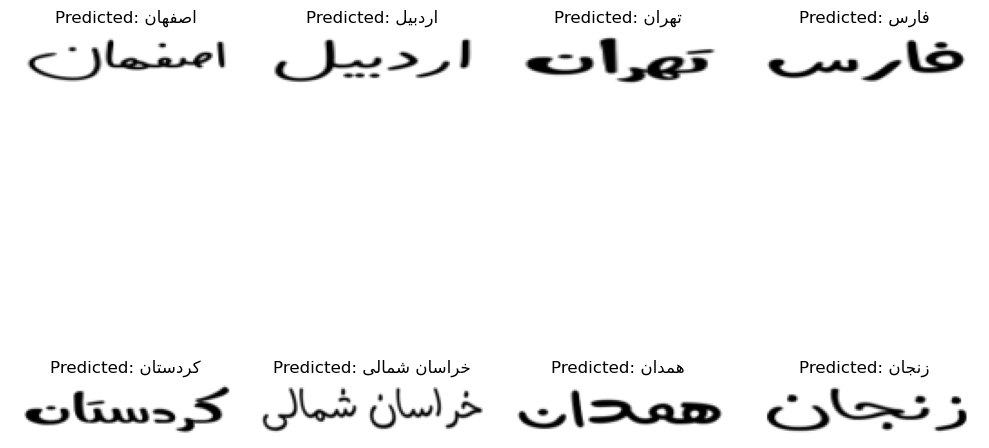

In [70]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

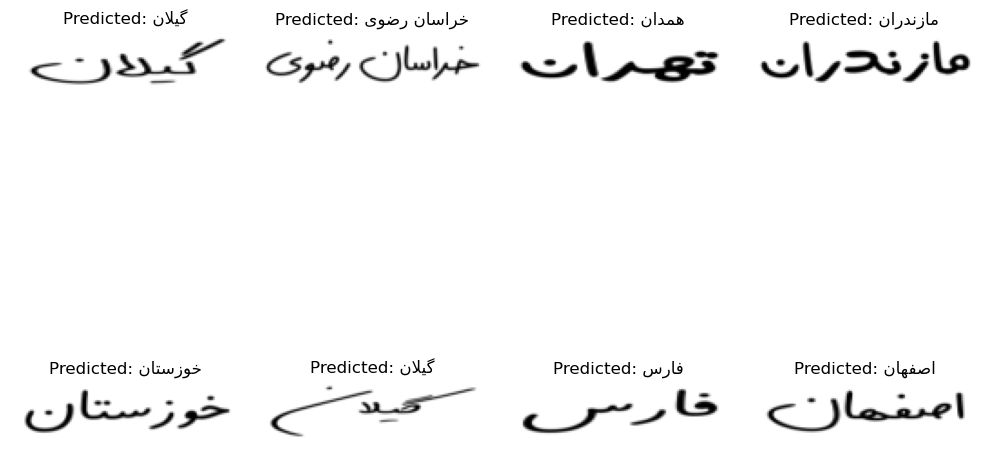

In [73]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

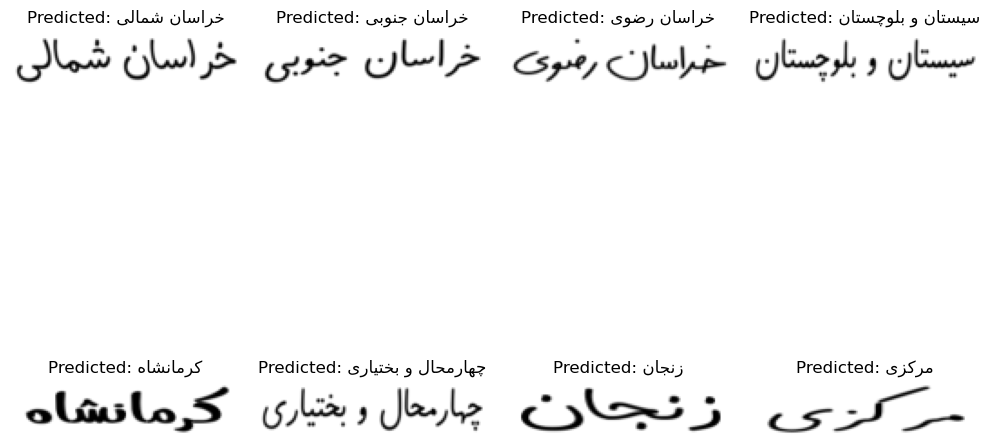

In [78]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

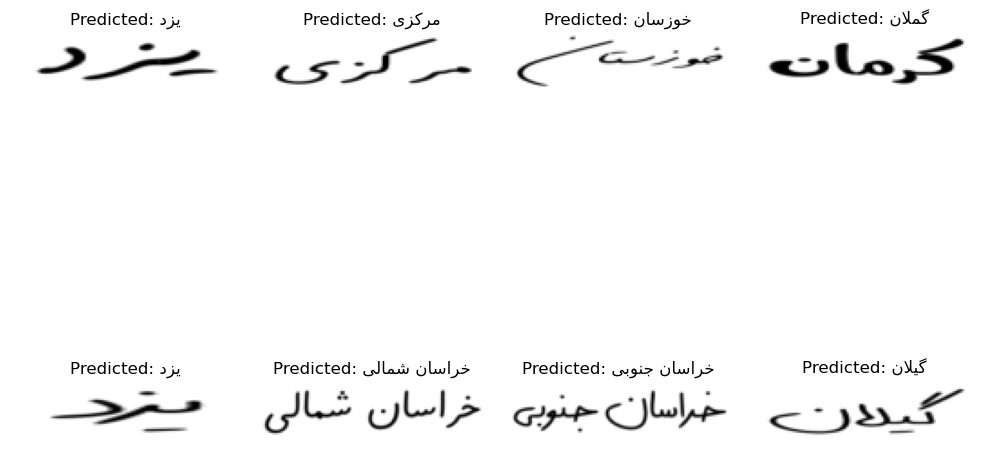

In [84]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

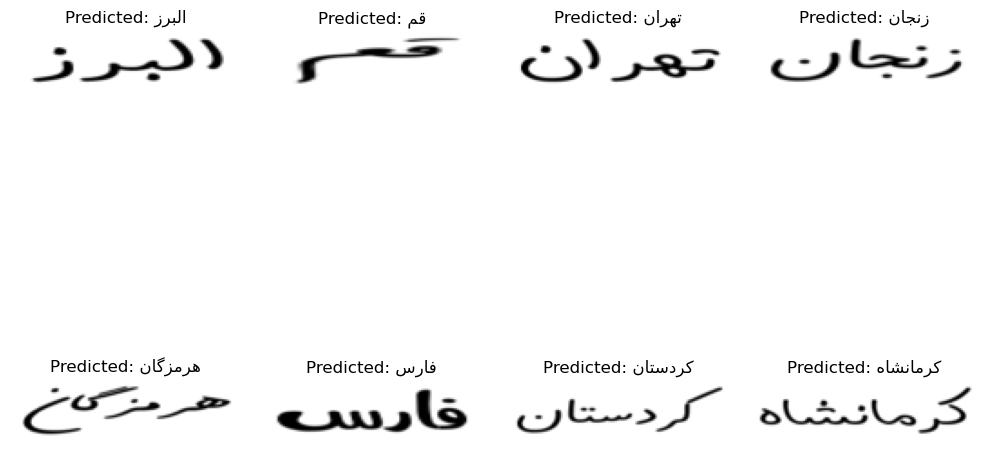

In [108]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

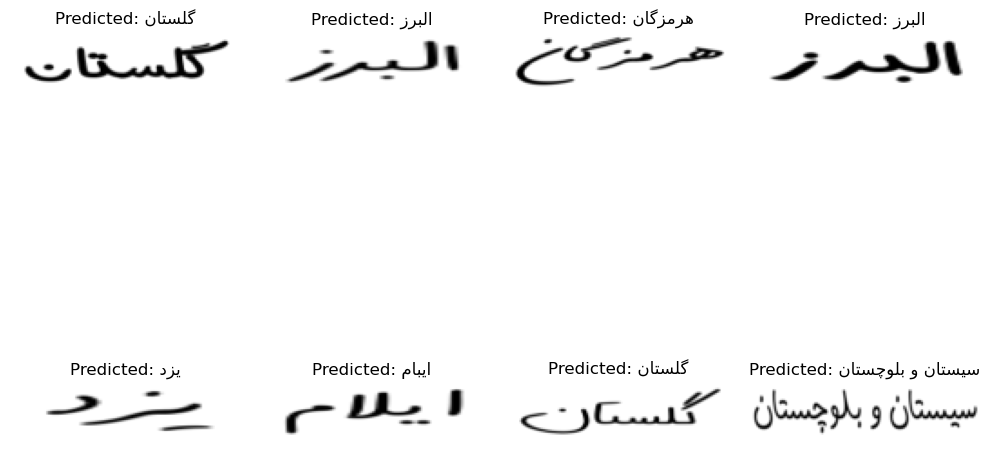

In [112]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')

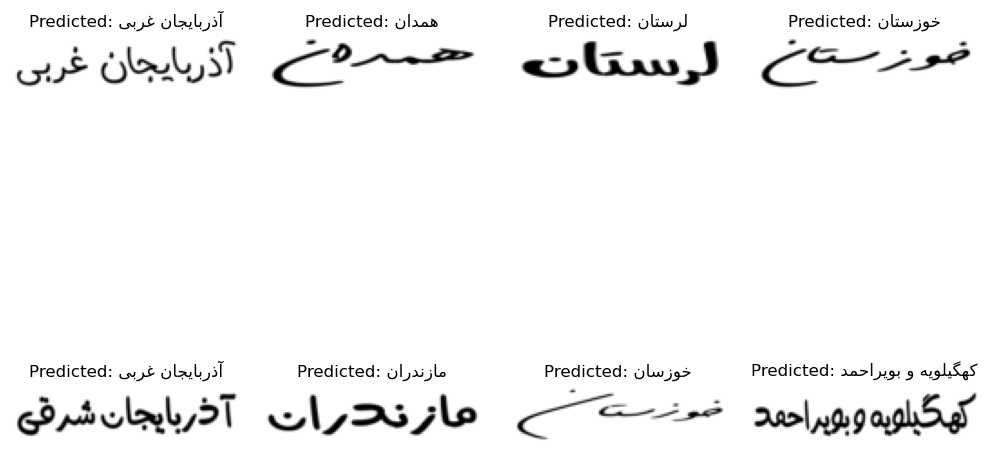

In [118]:
plot_batch_predictions(test_loader, model2, converter, 'cuda')